# What makes customers leave bad reviews?
### An analysis of 96,000 marketplace orders with SQL and Python (Olist, Brazil 2016–2018)

On a marketplace, a bad review hurts twice: the buyer is unhappy, and future buyers trust the platform less. In this project I use the [Olist Brazilian E-Commerce dataset](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) to find out **which orders end up with a bad review (1 or 2 stars) and what the marketplace could do about it.**

**How the project works**

1. **SQL (DuckDB):** I load the 9 raw tables, check data quality, and use JOINs, CTEs and window functions to build one clean table with **one row per delivered order**.
2. **Python (pandas, matplotlib, statsmodels):** I explore that table, test the differences statistically and fit a logistic regression model.

### Key findings

1. **Late delivery is the biggest driver.** 54% of late orders get a bad review, compared with 9% of on-time orders. The jump happens fast: orders 4–7 days late already get 62% bad reviews.
2. **Orders from two or more sellers are a hidden problem.** They get bad reviews **47% of the time even when delivered on time**, five times the rate of single-seller orders.
3. **Busy periods break delivery.** Black Friday (Nov 2017) and Feb–Mar 2018 had spikes in late deliveries, and bad reviews spiked in the same months.
4. **Distance matters only because it causes delays.** Once lateness is accounted for, distance has no extra negative effect.
5. **Some sellers are much worse than others.** 29 sellers have at least twice the average bad review rate. They handle 2.5% of orders but cause 6.5% of bad reviews.

**Estimated impact:** if late orders were reviewed like on-time orders, **about 28% of all bad reviews would disappear.**

## 1. Setup

Download the dataset from [Kaggle](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) and put the CSV files in a folder called `data/` next to this notebook. You'll need `duckdb` (`pip install duckdb`) alongside the usual pandas, matplotlib, scipy, statsmodels and scikit-learn.

In [1]:
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy import stats
import statsmodels.formula.api as smf
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

pd.set_option('display.float_format', '{:,.3f}'.format)

# chart style: light surface, quiet axes, one main colour and one highlight colour
BLUE, ORANGE = '#2a78d6', '#eb6834'
INK, INK_2, MUTED, GRID = '#0b0b0b', '#52514e', '#898781', '#e1e0d9'
plt.rcParams.update({
    'figure.figsize': (9, 4.5), 'figure.dpi': 110,
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': INK_2,
    'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.titlecolor': INK, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'axes.grid.axis': 'y', 'grid.color': GRID, 'grid.linewidth': 0.8,
    'axes.axisbelow': True, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'xtick.labelcolor': INK_2, 'ytick.labelcolor': INK_2,
    'legend.frameon': False, 'font.size': 10,
})
pct = mtick.PercentFormatter(1.0, decimals=0)

## 2. Load the raw tables into DuckDB

DuckDB is an in-process SQL database, so the SQL runs right here in the notebook without a server.

In [2]:
con = duckdb.connect()

files = {
    'orders':               'olist_orders_dataset',
    'order_items':          'olist_order_items_dataset',
    'order_reviews':        'olist_order_reviews_dataset',
    'order_payments':       'olist_order_payments_dataset',
    'customers':            'olist_customers_dataset',
    'sellers':              'olist_sellers_dataset',
    'products':             'olist_products_dataset',
    'category_translation': 'product_category_name_translation',
    'geolocation':          'olist_geolocation_dataset',
}
for table, file in files.items():
    con.execute(f"CREATE OR REPLACE TABLE {table} AS SELECT * FROM read_csv_auto('data/{file}.csv')")

def sql(query):
    # run a SQL query and return the result as a pandas DataFrame
    return con.execute(query).df()

### How the tables connect

```
customers ──customer_id── orders ──order_id── order_items ──product_id── products ── category_translation
                             │                     └──seller_id── sellers
                             ├──order_id── order_reviews
                             └──order_id── order_payments
customers / sellers ──zip_code_prefix── geolocation
```

In [3]:
sql('''
SELECT 'orders'         AS table_name, COUNT(*) AS rows FROM orders         UNION ALL
SELECT 'order_items',                  COUNT(*)         FROM order_items    UNION ALL
SELECT 'order_reviews',                COUNT(*)         FROM order_reviews  UNION ALL
SELECT 'order_payments',               COUNT(*)         FROM order_payments UNION ALL
SELECT 'customers',                    COUNT(*)         FROM customers      UNION ALL
SELECT 'sellers',                      COUNT(*)         FROM sellers        UNION ALL
SELECT 'products',                     COUNT(*)         FROM products       UNION ALL
SELECT 'geolocation',                  COUNT(*)         FROM geolocation
''')

,table_name,rows
0,orders,99441
1,order_items,112650
2,order_reviews,99224
3,order_payments,103886
4,customers,99441
5,sellers,3095
6,products,32951
7,geolocation,1000163


## 3. Data quality checks (SQL)

Before joining, I check the problems that would silently break a JOIN: rows that would be counted twice, and rows that have no match.

### 3.1 Order status

In [4]:
sql('''
SELECT
    order_status,
    COUNT(*)                                   AS orders,
    COUNT(order_delivered_customer_date)       AS with_delivery_date,
    ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct_of_orders
FROM orders
GROUP BY order_status
ORDER BY orders DESC
''')

,order_status,orders,with_delivery_date,pct_of_orders
0,delivered,96478,96470,97.020
1,shipped,1107,0,1.110
2,canceled,625,6,0.630
3,unavailable,609,0,0.610
4,invoiced,314,0,0.320
5,processing,301,0,0.300
6,created,5,0,0.010
7,approved,2,0,0.000


97% of orders were delivered. I only analyse **delivered orders with a delivery date**, since lateness can't be measured for the others. (8 "delivered" orders have no delivery date and are dropped.)

### 3.2 Reviews: one per order?

In [5]:
sql('''
SELECT
    reviews_per_order,
    COUNT(*) AS orders
FROM (
    SELECT order_id, COUNT(*) AS reviews_per_order
    FROM order_reviews
    GROUP BY order_id
) AS t
GROUP BY reviews_per_order
ORDER BY reviews_per_order
''')

,reviews_per_order,orders
0,1,98126
1,2,543
2,3,4


About 550 orders have 2 or 3 reviews. Joining reviews as-is would duplicate those orders, so I keep only the **most recent review** per order using `ROW_NUMBER()`.

### 3.3 Items and sellers per order

In [6]:
sql('''
WITH per_order AS (
    SELECT
        order_id,
        COUNT(*)                  AS items,
        COUNT(DISTINCT seller_id) AS sellers
    FROM order_items
    GROUP BY order_id
)
SELECT
    sellers,
    COUNT(*)                                            AS orders,
    ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2)  AS pct_of_orders,
    ROUND(AVG(items), 2)                                AS avg_items
FROM per_order
GROUP BY sellers
ORDER BY sellers
''')

,sellers,orders,pct_of_orders,avg_items
0,1,97388,98.700,1.120
1,2,1219,1.240,2.360
2,3,54,0.050,3.740
3,4,3,0.000,4.000
4,5,2,0.000,6.500


An order can have several items from several sellers, so `order_items` has more rows than `orders`. I **aggregate items to one row per order before joining**. For the order's category and seller I use the **most expensive item** (`ARG_MAX`).

### 3.4 Missing categories and locations

In [7]:
sql('''
SELECT 'products with no category'                AS check_name,
       COUNT(*) AS rows
FROM products
WHERE product_category_name IS NULL
UNION ALL
SELECT 'categories with no English translation',
       COUNT(DISTINCT p.product_category_name)
FROM products AS p
LEFT JOIN category_translation AS t USING (product_category_name)
WHERE t.product_category_name IS NULL AND p.product_category_name IS NOT NULL
UNION ALL
SELECT 'customers whose zip code has no coordinates',
       COUNT(*)
FROM customers AS c
LEFT JOIN (SELECT DISTINCT geolocation_zip_code_prefix AS zip FROM geolocation) AS g
       ON c.customer_zip_code_prefix = g.zip
WHERE g.zip IS NULL
UNION ALL
SELECT 'geolocation points outside Brazil',
       COUNT(*)
FROM geolocation
WHERE geolocation_lat NOT BETWEEN -34 AND 5.5
   OR geolocation_lng NOT BETWEEN -74 AND -34
''')

,check_name,rows
0,products with no category,610
1,categories with no English translation,2
2,customers whose zip code has no coordinates,278
3,geolocation points outside Brazil,42


These are small, and I handle each one in the main query:

- Products with no category are labelled `unknown`, and the 2 untranslated categories keep their Portuguese name.
- Missing coordinates leave the distance empty (`LEFT JOIN`).
- Points outside Brazil are filtered out before averaging coordinates per zip code.

## 4. Build the analysis table with JOINs (SQL)

This query combines all 9 tables into **one row per delivered, reviewed order**. It uses:

- **CTEs** to prepare each table: latest review, items rolled up per order, payments per order, coordinates per zip code;
- **`ROW_NUMBER()`** to remove duplicate reviews;
- **`ARG_MAX`** to pick the most expensive item's category and seller;
- **`INNER JOIN`** where a match is required and **`LEFT JOIN`** where data can be missing;
- the **haversine formula** to compute the distance between seller and customer:

$$d = 2R \arcsin\sqrt{\sin^2\!\left(\frac{\Delta\varphi}{2}\right) + \cos\varphi_1 \cos\varphi_2 \sin^2\!\left(\frac{\Delta\lambda}{2}\right)}$$

where $\varphi$ is latitude, $\lambda$ is longitude (in radians) and $R = 6371$ km is the Earth's radius.

A **bad review** is a score of 1 or 2 stars. An order is **late** if it arrived after the delivery date promised at purchase.

In [8]:
order_level_query = '''
WITH
-- 1. one review per order: keep the most recent answer
latest_review AS (
    SELECT
        order_id,
        review_score,
        review_comment_message IS NOT NULL AS has_comment,
        ROW_NUMBER() OVER (PARTITION BY order_id
                           ORDER BY review_answer_timestamp DESC) AS rn
    FROM order_reviews
),

-- 2. item lines with product category (in English) and seller location
items AS (
    SELECT
        oi.order_id,
        oi.seller_id,
        oi.price,
        oi.freight_value,
        p.product_weight_g,
        p.product_photos_qty,
        COALESCE(t.product_category_name_english,
                 p.product_category_name, 'unknown') AS category,
        s.seller_state,
        s.seller_zip_code_prefix
    FROM order_items AS oi
    LEFT JOIN products AS p
           ON oi.product_id = p.product_id
    LEFT JOIN category_translation AS t
           ON p.product_category_name = t.product_category_name
    LEFT JOIN sellers AS s
           ON oi.seller_id = s.seller_id
),

-- 3. roll items up to one row per order; the "main" item is the most expensive one
items_per_order AS (
    SELECT
        order_id,
        COUNT(*)                                   AS n_items,
        COUNT(DISTINCT seller_id)                  AS n_sellers,
        SUM(price)                                 AS items_value,
        SUM(freight_value)                         AS freight_value,
        SUM(product_weight_g)                      AS total_weight_g,
        ARG_MAX(category, price)                   AS main_category,
        ARG_MAX(seller_id, price)                  AS main_seller_id,
        ARG_MAX(seller_state, price)               AS seller_state,
        ARG_MAX(seller_zip_code_prefix, price)     AS seller_zip,
        MIN(product_photos_qty)                    AS min_photos
    FROM items
    GROUP BY order_id
),

-- 4. payments: total paid, main payment method, number of instalments
payments_per_order AS (
    SELECT
        order_id,
        SUM(payment_value)                         AS payment_value,
        ARG_MAX(payment_type, payment_value)       AS payment_type,
        MAX(payment_installments)                  AS installments
    FROM order_payments
    GROUP BY order_id
),

-- 5. one coordinate per zip code prefix (average of all points)
zip_coords AS (
    SELECT
        geolocation_zip_code_prefix                AS zip,
        AVG(geolocation_lat)                       AS lat,
        AVG(geolocation_lng)                       AS lng
    FROM geolocation
    -- some points are outside Brazil (bad data), so keep only Brazil's bounding box
    WHERE geolocation_lat BETWEEN -34 AND 5.5
      AND geolocation_lng BETWEEN -74 AND -34
    GROUP BY geolocation_zip_code_prefix
)

-- 6. put it all together: one row per delivered, reviewed order
SELECT
    o.order_id,
    c.customer_unique_id,
    o.order_purchase_timestamp                                         AS purchased_at,
    DATE_TRUNC('month', o.order_purchase_timestamp)                    AS purchase_month,
    DATE_DIFF('hour', o.order_purchase_timestamp,
                      o.order_delivered_customer_date) / 24.0          AS delivery_days,
    DATE_DIFF('hour', o.order_purchase_timestamp,
                      o.order_estimated_delivery_date) / 24.0          AS promised_days,
    DATE_DIFF('hour', o.order_estimated_delivery_date,
                      o.order_delivered_customer_date) / 24.0          AS days_late,
    o.order_delivered_customer_date > o.order_estimated_delivery_date  AS is_late,
    i.n_items,
    i.n_sellers,
    i.items_value,
    i.freight_value,
    i.total_weight_g,
    i.main_category,
    i.main_seller_id,
    i.min_photos,
    p.payment_type,
    p.installments,
    c.customer_state,
    i.seller_state,
    c.customer_state = i.seller_state                                  AS same_state,
    -- great-circle (haversine) distance between seller and customer, in km
    2 * 6371 * ASIN(SQRT(
          POWER(SIN(RADIANS(gc.lat - gs.lat) / 2), 2)
        + COS(RADIANS(gs.lat)) * COS(RADIANS(gc.lat))
        * POWER(SIN(RADIANS(gc.lng - gs.lng) / 2), 2)))                AS distance_km,
    r.review_score,
    r.review_score <= 2                                                AS bad_review,
    r.has_comment
FROM orders AS o
INNER JOIN customers AS c
        ON o.customer_id = c.customer_id
INNER JOIN latest_review AS r
        ON o.order_id = r.order_id AND r.rn = 1
INNER JOIN items_per_order AS i
        ON o.order_id = i.order_id
LEFT JOIN payments_per_order AS p
        ON o.order_id = p.order_id
LEFT JOIN zip_coords AS gc
        ON c.customer_zip_code_prefix = gc.zip
LEFT JOIN zip_coords AS gs
        ON i.seller_zip = gs.zip
WHERE o.order_status = 'delivered'
  AND o.order_delivered_customer_date IS NOT NULL
'''

con.execute('CREATE OR REPLACE TABLE order_level AS ' + order_level_query)
df = sql('SELECT * FROM order_level')
print(f'{len(df):,} orders, {df.order_id.nunique():,} unique order IDs, {df.shape[1]} columns')
df.head()

95,824 orders, 95,824 unique order IDs, 25 columns


,order_id,customer_unique_id,purchased_at,purchase_month,delivery_days,promised_days,days_late,is_late,n_items,n_sellers,...,min_photos,payment_type,installments,customer_state,seller_state,same_state,distance_km,review_score,bad_review,has_comment
0,00e7ee1b050b8499577073aeb2a297a1,861eff4711a542e4b93843c6dd7febb0,2017-05-16 15:05:35,2017-05-01,8.792,19.375,-10.583,False,1,1,...,1,credit_card,2,SP,SP,True,348.771,4,False,False
1,29150127e6685892b6eab3eec79f59c7,290c77bc529b7ac935b93aa66c333dc3,2018-01-12 20:48:24,2018-01-01,16.667,24.167,-7.500,False,1,1,...,3,credit_card,8,SP,SC,False,413.832,5,False,False
2,b2059ed67ce144a36e2aa97d2c9e9ad2,060e732b5b29e8181a18229c7b0b2b5e,2018-05-19 16:07:45,2018-05-01,26.042,24.333,1.708,True,1,1,...,1,credit_card,7,SP,SP,True,29.957,5,False,False
3,951670f92359f4fe4a63112aa7306eba,259dac757896d24d7702b9acbbff3f3c,2018-03-13 16:06:38,2018-03-01,15.000,27.333,-12.333,False,1,1,...,1,credit_card,1,SP,SP,True,18.569,5,False,False
4,6b7d50bd145f6fc7f33cebabd7e49d0f,345ecd01c38d18a9036ed96c73b8d066,2018-07-29 09:51:30,2018-07-01,11.458,16.625,-5.167,False,1,1,...,1,credit_card,8,SP,SP,True,220.047,5,False,True


### A first look in SQL: late vs on-time orders

In [9]:
sql('''
SELECT
    CASE WHEN is_late THEN 'late' ELSE 'on time' END        AS delivery,
    COUNT(*)                                                AS orders,
    ROUND(AVG(review_score), 2)                             AS avg_score,
    ROUND(100.0 * AVG(bad_review::INT), 1)                  AS pct_bad_reviews,
    ROUND(AVG(delivery_days), 1)                            AS avg_delivery_days
FROM order_level
GROUP BY delivery
ORDER BY delivery
''')

,delivery,orders,avg_score,pct_bad_reviews,avg_delivery_days
0,late,7661,2.570,54.100,31.400
1,on time,88163,4.290,9.200,10.900


The difference is huge: late orders average **2.6 stars** against **4.3**. The rest of the analysis is in Python.

## 5. Analysis (Python)

### 5.1 How are review scores distributed?

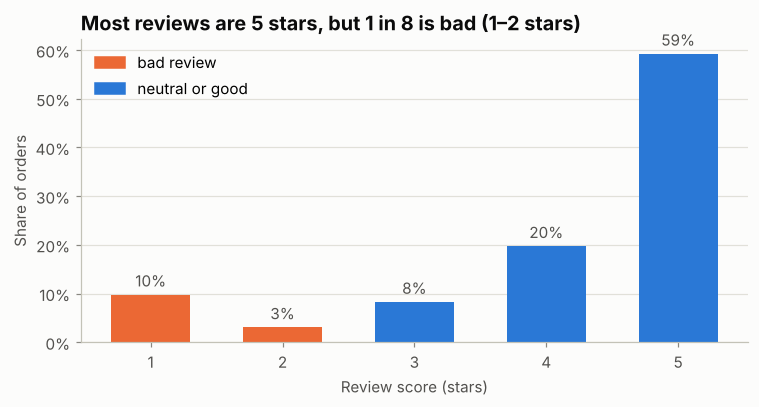

Bad review rate overall: 12.8%


In [10]:
scores = df.review_score.value_counts(normalize=True).sort_index()

fig, ax = plt.subplots(figsize=(7, 3.8))
colors = [ORANGE if s <= 2 else BLUE for s in scores.index]
bars = ax.bar(scores.index.astype(str), scores.values, color=colors, width=0.6)
ax.bar_label(bars, labels=[f'{v:.0%}' for v in scores.values], padding=3, color=INK_2)
ax.yaxis.set_major_formatter(pct)
ax.set_xlabel('Review score (stars)')
ax.set_ylabel('Share of orders')
ax.set_title('Most reviews are 5 stars, but 1 in 8 is bad (1–2 stars)')
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=ORANGE), plt.Rectangle((0, 0), 1, 1, color=BLUE)],
          labels=['bad review', 'neutral or good'], loc='upper left')
plt.tight_layout(); plt.show()

print(f'Bad review rate overall: {df.bad_review.mean():.1%}')

Reviews are very positive overall, which is typical for marketplaces. So the **12.8% of bad reviews** stand out, and they're what I try to explain.

### 5.2 Delivery: how late is too late?

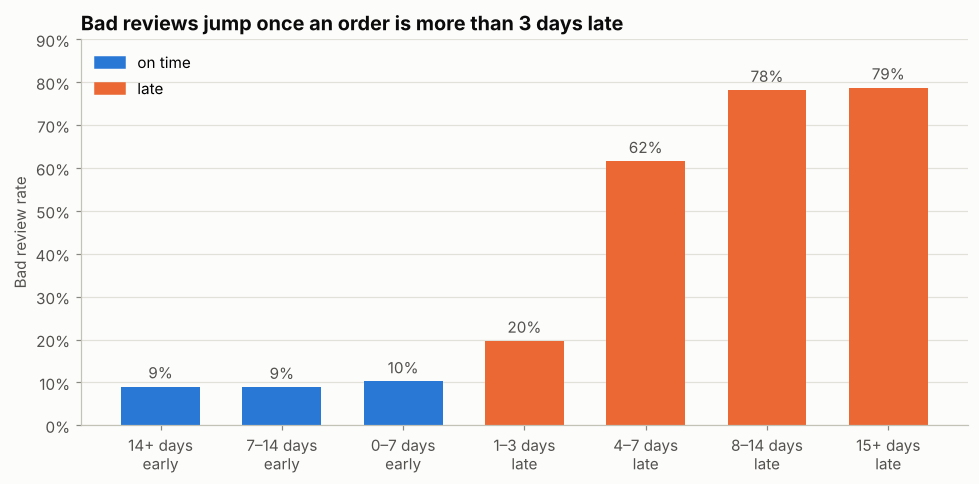

,orders,bad_rate
late_bucket,,
14+ days\nearly,34924,0.090
7–14 days\nearly,36163,0.089
0–7 days\nearly,17129,0.102
1–3 days\nlate,2597,0.197
4–7 days\nlate,1786,0.616
8–14 days\nlate,1724,0.782
15+ days\nlate,1501,0.787


In [11]:
bins   = [-np.inf, -14, -7, 0, 3, 7, 14, np.inf]
labels = ['14+ days\nearly', '7–14 days\nearly', '0–7 days\nearly',
          '1–3 days\nlate', '4–7 days\nlate', '8–14 days\nlate', '15+ days\nlate']
df['late_bucket'] = pd.cut(df.days_late, bins=bins, labels=labels)

by_lateness = df.groupby('late_bucket', observed=True).agg(
    orders=('order_id', 'size'), bad_rate=('bad_review', 'mean'))

fig, ax = plt.subplots()
colors = [BLUE] * 3 + [ORANGE] * 4
bars = ax.bar(by_lateness.index.astype(str), by_lateness.bad_rate, color=colors, width=0.65)
ax.bar_label(bars, labels=[f'{v:.0%}' for v in by_lateness.bad_rate], padding=3, color=INK_2)
ax.yaxis.set_major_formatter(pct)
ax.set_ylim(0, 0.9)
ax.set_ylabel('Bad review rate')
ax.set_title('Bad reviews jump once an order is more than 3 days late')
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=BLUE), plt.Rectangle((0, 0), 1, 1, color=ORANGE)],
          labels=['on time', 'late'], loc='upper left')
plt.tight_layout(); plt.show()

by_lateness

In [12]:
# Is the difference between late and on-time orders statistically significant?
table = pd.crosstab(df.is_late, df.bad_review)
chi2, p_value, _, _ = stats.chi2_contingency(table)
print(f'Chi-square = {chi2:,.0f}, p-value = {p_value:.1e}')
print('p < 0.001' if p_value < 0.001 else f'p = {p_value:.3f}')
print(f'Share of orders that are late: {df.is_late.mean():.1%}')

Chi-square = 12,690, p-value = 0.0e+00
p < 0.001
Share of orders that are late: 8.0%


- Orders that arrive early are reviewed the same way (about **9% bad**) whether they're 2 days or 2 weeks early. Arriving **very early earns no extra credit**.
- **1–3 days late** doubles the bad rate to 20%. **4–7 days late** triples it again to **62%**, and beyond a week almost **4 in 5** reviews are bad.
- The chi-square test confirms the late vs on-time difference is far too large to be chance ($p < 0.001$).

Only 8% of orders are late, but they cause a large share of bad reviews.

### 5.3 Does a long (but on-time) delivery also hurt?

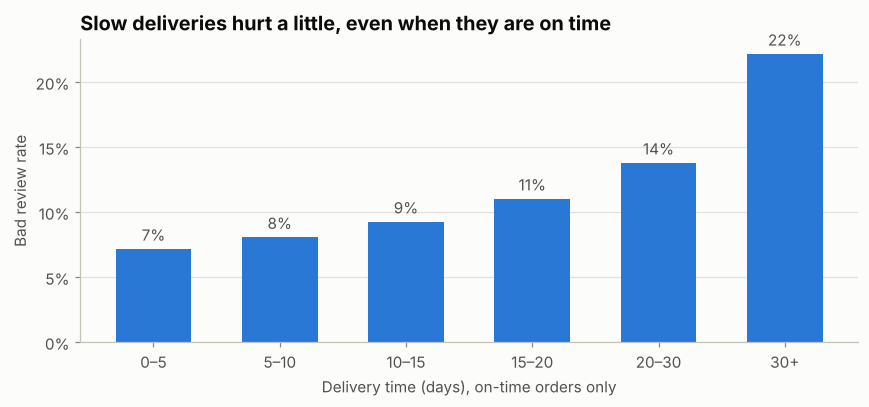

,orders,bad_rate
delivery_bucket,,
0–5,13434,0.072
5–10,32583,0.081
10–15,22974,0.093
15–20,11467,0.110
20–30,6880,0.138
30+,825,0.222


In [13]:
on_time = df[~df.is_late].copy()
on_time['delivery_bucket'] = pd.cut(on_time.delivery_days, [0, 5, 10, 15, 20, 30, np.inf],
                                    labels=['0–5', '5–10', '10–15', '15–20', '20–30', '30+'])
by_speed = on_time.groupby('delivery_bucket', observed=True).agg(
    orders=('order_id', 'size'), bad_rate=('bad_review', 'mean'))

fig, ax = plt.subplots(figsize=(8, 3.8))
bars = ax.bar(by_speed.index.astype(str), by_speed.bad_rate, color=BLUE, width=0.6)
ax.bar_label(bars, labels=[f'{v:.0%}' for v in by_speed.bad_rate], padding=3, color=INK_2)
ax.yaxis.set_major_formatter(pct)
ax.set_xlabel('Delivery time (days), on-time orders only')
ax.set_ylabel('Bad review rate')
ax.set_title('Slow deliveries hurt a little, even when they are on time')
plt.tight_layout(); plt.show()
by_speed

Even among on-time orders, the bad rate rises from **7%** for deliveries under 5 days to **14%** for 20–30 days. That's a real effect, but much smaller than being late. **Keeping the promise matters more than being fast.**

### 5.4 Over time: busy months break delivery

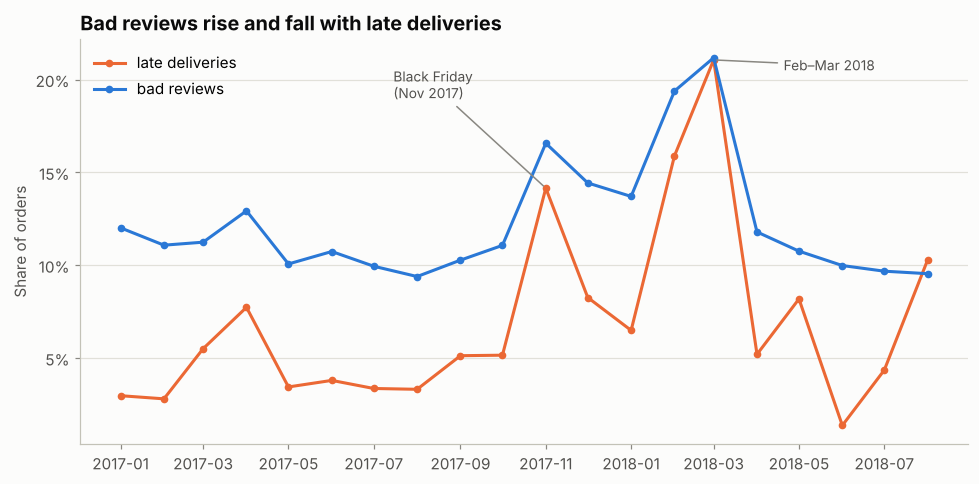

Correlation between monthly late rate and bad review rate: 0.88


In [14]:
monthly = (df[(df.purchase_month >= '2017-01-01')]
           .groupby('purchase_month')
           .agg(orders=('order_id', 'size'), late_rate=('is_late', 'mean'), bad_rate=('bad_review', 'mean')))

fig, ax = plt.subplots()
ax.yaxis.set_major_locator(mtick.MultipleLocator(0.05))
ax.plot(monthly.index, monthly.late_rate, color=ORANGE, lw=2, marker='o', ms=4, label='late deliveries')
ax.plot(monthly.index, monthly.bad_rate, color=BLUE, lw=2, marker='o', ms=4, label='bad reviews')
ax.yaxis.set_major_formatter(pct)
ax.set_ylabel('Share of orders')
ax.set_title('Bad reviews rise and fall with late deliveries')
ax.annotate('Black Friday\n(Nov 2017)', xy=(pd.Timestamp('2017-11-01'), monthly.loc['2017-11-01', 'late_rate']),
            xytext=(pd.Timestamp('2017-07-15'), 0.19), color=INK_2, fontsize=9,
            arrowprops=dict(arrowstyle='-', color=MUTED))
ax.annotate('Feb–Mar 2018', xy=(pd.Timestamp('2018-03-01'), monthly.loc['2018-03-01', 'late_rate']),
            xytext=(pd.Timestamp('2018-04-20'), 0.205), color=INK_2, fontsize=9,
            arrowprops=dict(arrowstyle='-', color=MUTED))
ax.legend(loc='upper left')
plt.tight_layout(); plt.show()

print(f"Correlation between monthly late rate and bad review rate: {monthly.late_rate.corr(monthly.bad_rate):.2f}")

The two lines move together. Late deliveries spiked to **14%** in November 2017 (Black Friday) and **21%** in March 2018, and bad reviews peaked in the same months. Across months, the two rates have a correlation of **0.88**. This points to **capacity problems in busy periods** that the platform can plan for.

### 5.5 Orders from several sellers

In [15]:
df['sellers_group'] = np.where(df.n_sellers > 1, '2+ sellers', '1 seller')
df['delivery'] = np.where(df.is_late, 'late', 'on time')

multi = (df.groupby(['sellers_group', 'delivery'])
           .agg(orders=('order_id', 'size'), bad_rate=('bad_review', 'mean'))
           .reset_index())
multi

,sellers_group,delivery,orders,bad_rate
0,1 seller,late,7644,0.540
1,1 seller,on time,86919,0.087
2,2+ sellers,late,17,0.706
3,2+ sellers,on time,1244,0.469


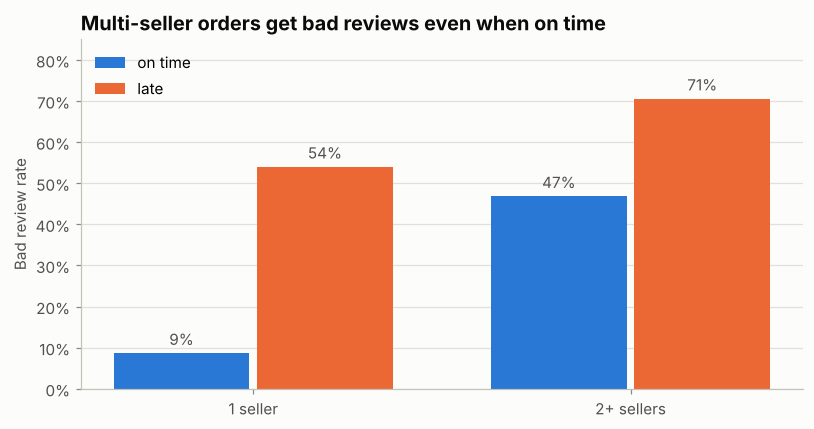

1,261 multi-seller orders (1.3% of orders), 4.8% of all bad reviews


In [16]:
pivot = multi.pivot(index='sellers_group', columns='delivery', values='bad_rate')[['on time', 'late']]

fig, ax = plt.subplots(figsize=(7.5, 4))
x = np.arange(len(pivot.index)); w = 0.36
b1 = ax.bar(x - w/2 - 0.01, pivot['on time'], w, color=BLUE, label='on time')
b2 = ax.bar(x + w/2 + 0.01, pivot['late'], w, color=ORANGE, label='late')
for b in (b1, b2):
    ax.bar_label(b, labels=[f'{v:.0%}' for v in b.datavalues], padding=3, color=INK_2)
ax.set_xticks(x, pivot.index)
ax.yaxis.set_major_formatter(pct)
ax.set_ylim(0, 0.85)
ax.set_ylabel('Bad review rate')
ax.set_title('Multi-seller orders get bad reviews even when on time')
ax.legend(loc='upper left')
plt.tight_layout(); plt.show()

n_multi = (df.n_sellers > 1).sum()
print(f'{n_multi:,} multi-seller orders ({n_multi / len(df):.1%} of orders), '
      f'{df.loc[df.n_sellers > 1, "bad_review"].sum() / df.bad_review.sum():.1%} of all bad reviews')

This is the most surprising result. Orders with items from **two or more sellers** get a bad review **47% of the time even when they arrive on time**, compared with 9% for single-seller orders. (The 71% for late multi-seller orders is based on only 17 orders, so I don't read much into it.)

A likely reason is that each seller ships separately, so the parcels arrive at different times. If the customer is asked to review when the first parcel arrives, part of the order is still missing. (The data records only one delivery date per order, so I can't confirm this directly.) Multi-seller orders are only 1.3% of orders but cause 4.8% of all bad reviews. The total impact is small today, but it would grow as more customers buy from several sellers at once, which is a common pattern on marketplaces.

### 5.6 Product categories

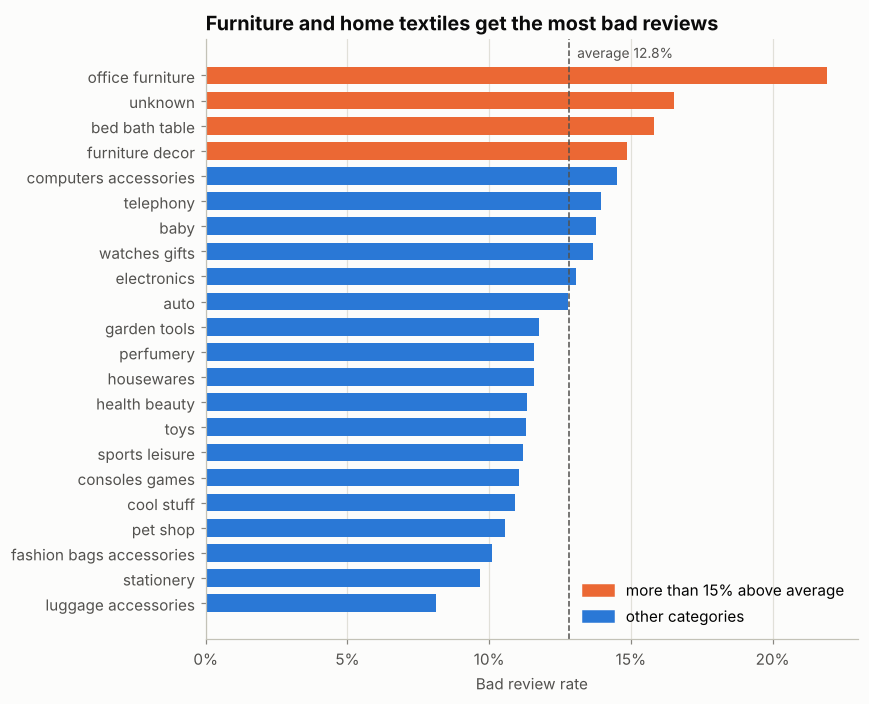

,orders,bad_rate,late_rate
main_category,,,
office_furniture,1241,0.219,0.090
unknown,1349,0.165,0.088
bed_bath_table,9090,0.158,0.086
furniture_decor,6142,0.148,0.085
computers_accessories,6480,0.145,0.076
telephony,4049,0.139,0.085


In [17]:
cat = (df.groupby('main_category')
         .agg(orders=('order_id', 'size'), bad_rate=('bad_review', 'mean'), late_rate=('is_late', 'mean'))
         .query('orders >= 1000')
         .sort_values('bad_rate'))
avg_bad = df.bad_review.mean()

fig, ax = plt.subplots(figsize=(8, 6.5))
colors = [ORANGE if r > avg_bad * 1.15 else BLUE for r in cat.bad_rate]
ax.barh(cat.index.str.replace('_', ' '), cat.bad_rate, color=colors, height=0.7)
ax.axvline(avg_bad, color=INK_2, lw=1, ls='--')
ax.text(avg_bad + 0.003, len(cat) - 0.3, f'average {avg_bad:.1%}', color=INK_2, fontsize=9)
ax.xaxis.set_major_formatter(pct)
ax.grid(axis='x'); ax.grid(axis='y', visible=False)
ax.set_xlabel('Bad review rate')
ax.set_title('Furniture and home textiles get the most bad reviews')
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=ORANGE), plt.Rectangle((0, 0), 1, 1, color=BLUE)],
          labels=['more than 15% above average', 'other categories'], loc='lower right')
plt.tight_layout(); plt.show()

cat.sort_values('bad_rate', ascending=False).head(6)

Among categories with 1,000+ orders, **office furniture (22%)**, **bed/bath/table (16%)** and **furniture & decor (15%)** get the most bad reviews. **Luggage, stationery and fashion bags** get the fewest (8–10%).

Large, bulky items are harder to ship, and products like furniture and bedding are easier to be disappointed by ("doesn't look like the photo"). The "unknown" category is also above average, which suggests listings with missing information do worse.

### 5.7 Distance between seller and customer

In [18]:
df['distance_group'] = pd.qcut(df.distance_km, 5,
                               labels=['shortest 20%', '2nd', '3rd', '4th', 'longest 20%'])
dist = df.groupby('distance_group', observed=True).agg(
    median_km=('distance_km', 'median'),
    late_rate=('is_late', 'mean'),
    bad_rate=('bad_review', 'mean'),
    bad_rate_on_time=('bad_review', lambda s: s[~df.loc[s.index, 'is_late']].mean()))
dist

,median_km,late_rate,bad_rate,bad_rate_on_time
distance_group,,,,
shortest 20%,34.428,0.064,0.104,0.084
2nd,276.461,0.067,0.123,0.092
3rd,433.684,0.075,0.129,0.092
4th,694.343,0.084,0.136,0.097
longest 20%,"1,455.771",0.108,0.150,0.098


Longer distances mean more late orders (6% → 11%) and more bad reviews (10% → 15%). But **among on-time orders, the bad rate rises only slightly** (8% → 10%). So distance hurts reviews mainly by causing delays, which the model in section 6 confirms.

### 5.8 Sellers: is it a few bad apples?

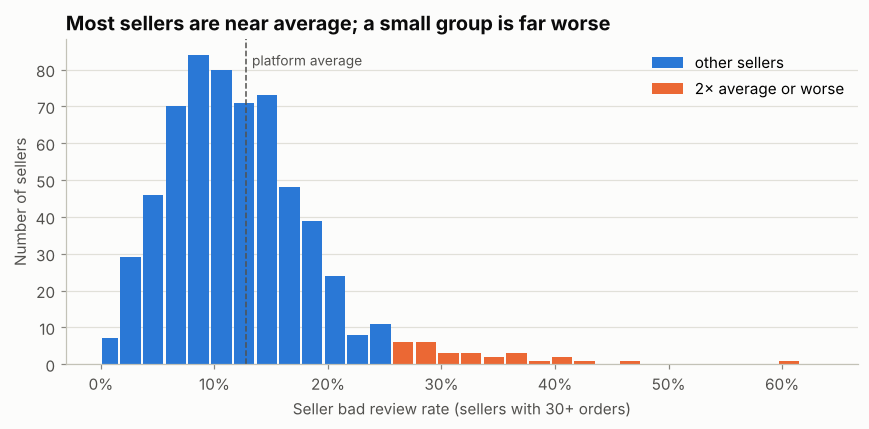

Sellers with 30+ orders: 619 (they handle 83% of orders)
"Problem" sellers (bad rate ≥ 26%): 29 sellers, 2.5% of orders, 6.5% of bad reviews
Correlation between a seller's late rate and bad review rate: 0.53


In [19]:
sellers = (df.groupby('main_seller_id')
             .agg(orders=('order_id', 'size'), bad_reviews=('bad_review', 'sum'),
                  bad_rate=('bad_review', 'mean'), late_rate=('is_late', 'mean')))
active = sellers[sellers.orders >= 30]          # enough orders for a fair rate
problem = active[active.bad_rate >= 2 * avg_bad]

fig, ax = plt.subplots(figsize=(8, 4))
threshold = 2 * avg_bad
# bin edges line up with the 2× threshold, so no bar mixes both groups
edges = np.unique(np.concatenate([[0], np.arange(threshold, 0, -0.02)[::-1], np.arange(threshold, 0.64, 0.02)]))
ax.hist(active.bad_rate[active.bad_rate < 2 * avg_bad], bins=edges, color=BLUE, rwidth=0.9, label='other sellers')
ax.hist(problem.bad_rate, bins=edges, color=ORANGE, rwidth=0.9, label='2× average or worse')
ax.axvline(avg_bad, color=INK_2, lw=1, ls='--')
ax.text(avg_bad + 0.005, ax.get_ylim()[1] * 0.92, 'platform average', color=INK_2, fontsize=9)
ax.xaxis.set_major_formatter(pct)
ax.set_xlabel('Seller bad review rate (sellers with 30+ orders)')
ax.set_ylabel('Number of sellers')
ax.set_title('Most sellers are near average; a small group is far worse')
ax.legend(loc='upper right')
plt.tight_layout(); plt.show()

print(f'Sellers with 30+ orders: {len(active):,} (they handle {active.orders.sum() / len(df):.0%} of orders)')
print(f'"Problem" sellers (bad rate ≥ {2 * avg_bad:.0%}): {len(problem)} sellers, '
      f'{problem.orders.sum() / len(df):.1%} of orders, {problem.bad_reviews.sum() / df.bad_review.sum():.1%} of bad reviews')
print(f'Correlation between a seller\'s late rate and bad review rate: {active.late_rate.corr(active.bad_rate):.2f}')

Most active sellers sit close to the platform average, but **29 "problem sellers"** have at least twice the average bad review rate. They handle only **2.5% of orders but cause 6.5% of bad reviews**, about 2.6 times their share. A seller's late delivery rate is strongly correlated with their bad review rate ($r = 0.53$), so **seller-side shipping delays are a big part of the story.**

This is useful for a marketplace: a short list of sellers to contact, coach or move down in search results.

## 6. Putting it together: logistic regression

The analyses above look at one factor at a time, but the factors overlap: long distances cause late orders, multi-seller orders have more items, and so on. A **logistic regression** estimates the effect of each factor *while holding the others constant*:

$$\log\left(\frac{p}{1-p}\right) = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_k x_k$$

where $p$ is the probability of a bad review. Each **odds ratio** $e^{\beta_j}$ tells how the odds of a bad review change when $x_j$ goes up by one unit: above 1 means more bad reviews, below 1 means fewer.

In [20]:
model_df = df.dropna(subset=['distance_km']).copy()
model_df['bad']           = model_df.bad_review.astype(int)
model_df['late']          = model_df.is_late.astype(int)
model_df['days_late']     = model_df.days_late.clip(lower=0, upper=30)   # extra days late (capped at 30)
model_df['multi_seller']  = (model_df.n_sellers > 1).astype(int)
model_df['multi_item']    = (model_df.n_items > 1).astype(int)
model_df['log_value']     = np.log1p(model_df.items_value)
model_df['freight_share'] = model_df.freight_value / (model_df.items_value + model_df.freight_value)
model_df['distance_1000km'] = model_df.distance_km / 1000

train, test = train_test_split(model_df, test_size=0.25, random_state=42, stratify=model_df.bad)

formula = ('bad ~ late + days_late + multi_seller + multi_item + log_value'
           ' + freight_share + distance_1000km + promised_days')
model = smf.logit(formula, data=train).fit(disp=False)

conf = np.exp(model.conf_int())
results = pd.DataFrame({
    'odds_ratio': np.exp(model.params),
    'ci_low': conf[0], 'ci_high': conf[1],
    'p_value': model.pvalues,
}).drop('Intercept')
labels_map = {
    'late': 'late delivery (yes/no)', 'days_late': 'each extra day late',
    'multi_seller': '2+ sellers', 'multi_item': '2+ items',
    'log_value': 'order value (log)', 'freight_share': 'freight share of price (0–1)',
    'distance_1000km': 'distance (per 1,000 km)', 'promised_days': 'each day of promised delivery time',
}
results.index = results.index.map(labels_map)
results.sort_values('odds_ratio', ascending=False)

,odds_ratio,ci_low,ci_high,p_value
late delivery (yes/no),4.974,4.538,5.452,0.000
2+ sellers,3.383,2.929,3.908,0.000
2+ items,2.776,2.571,2.999,0.000
freight share of price (0–1),1.976,1.387,2.815,0.000
each extra day late,1.148,1.137,1.160,0.000
order value (log),1.125,1.072,1.181,0.000
each day of promised delivery time,1.021,1.018,1.025,0.000
"distance (per 1,000 km)",0.900,0.855,0.946,0.000


In [21]:
auc = roc_auc_score(test.bad, model.predict(test))
print(f'AUC on unseen test orders: {auc:.3f}')

AUC on unseen test orders: 0.725


**How to read this:**

- **Being late multiplies the odds of a bad review by about 5**, and each extra day late adds about 15% more on top.
- **Multi-seller orders** have about **3.4× the odds**, even after controlling for lateness and number of items. Orders with **several items** are also riskier (about 2.8×).
- **Distance** has an odds ratio slightly *below* 1 once lateness is in the model, which confirms section 5.7: distance matters only because it causes delays.
- A **longer promised delivery time** slightly increases bad reviews (about 2% per day), so promising very late dates to avoid being late is not free either.

The model's **AUC of about 0.73** on unseen orders means it ranks a random bad-review order above a random good one about 73% of the time. That's reasonable for a model that only knows about logistics, not the product itself. It isn't meant to predict perfectly; it's meant to measure each factor's effect.

## 7. How many bad reviews could be prevented?

A simple what-if: if late orders got bad reviews at the same rate as on-time orders, how many bad reviews would remain?

In [22]:
on_time_rate = df.loc[~df.is_late, 'bad_review'].mean()
actual_bad   = df.bad_review.sum()
what_if_bad  = df.loc[~df.is_late, 'bad_review'].sum() + on_time_rate * df.is_late.sum()

print(f'Actual bad reviews:            {actual_bad:,.0f}')
print(f'If late orders behaved on time: {what_if_bad:,.0f}')
print(f'Reduction:                     {1 - what_if_bad / actual_bad:.0%}')

Actual bad reviews:            12,272
If late orders behaved on time: 8,836
Reduction:                     28%


Removing late deliveries would cut bad reviews by about **28%**, even though only 8% of orders are late. This is an upper bound: some late orders would get bad reviews anyway, and the analysis shows correlation, not proof of cause.

## 8. Recommendations

1. **Protect the delivery promise, especially in peak months.** Late delivery is the biggest driver, and spikes happen around Black Friday and early in the year. Add logistics capacity before known peaks, and alert customers *before* an order becomes late; customers forgive 1–3 days far more than a week.
2. **Fix the multi-seller experience.** Show customers that their items arrive in separate parcels, and send the review request only after *all* parcels are delivered.
3. **Work with problem sellers.** 29 sellers with a bad rate 2× the average or worse cause 2.6 times their share of bad reviews. Monitor sellers' late rates and step in early with coaching, shipping requirements or lower search ranking.
4. **Look closer at furniture and home textiles.** Better photos, size information and packaging rules could help the categories with the most bad reviews.

## 9. Limitations

- **Correlation, not causation.** Late orders and bad reviews may share hidden causes, such as a seller who ships late *and* sells poor products. An A/B test, for example on proactive delay alerts, would measure the true effect.
- **Review text not used.** Comments are in Portuguese and were left out; text analysis could show *why* customers complain.
- **One delivery date per order.** Multi-seller orders with several parcels can't be analysed parcel by parcel.
- **Data from 2016–2018 in Brazil.** Logistics and customer expectations may differ in other markets and today.

## Techniques used

**SQL (DuckDB):** multi-table `INNER`/`LEFT JOIN`s, CTEs, window functions (`ROW_NUMBER`, `SUM() OVER`), aggregation with `ARG_MAX`, `CASE`, `UNION ALL`, date arithmetic, haversine distance.
**Python:** pandas (groupby, binning with `cut`/`qcut`, pivots), matplotlib, chi-square test (scipy), logistic regression with odds ratios (statsmodels), train/test split and AUC (scikit-learn).